In [1]:
import os
import random
from copy import deepcopy
from pathlib import Path
from typing import Sequence

import albumentations as A
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pytorch_lightning as pl
import torch
import torch.nn as nn
import torch.nn.functional as F
from albumentations.pytorch import ToTensorV2
from PIL import Image
from tqdm.auto import tqdm

In [2]:
SEED = 1488
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BATCH_SIZE = 8
NUM_WORKERS = 0 

In [3]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)
print(f"DEVICE: {DEVICE}")

DEVICE: cuda


In [4]:
VOC_CLASSES = {
    0: "background",
    1: "aeroplane",
    2: "bicycle",
    3: "bird",
    4: "boat",
    5: "bottle",
    6: "bus",
    7: "car",
    8: "cat",
    9: "chair",
    10: "cow",
    11: "diningtable",
    12: "dog",
    13: "horse",
    14: "motorbike",
    15: "person",
    16: "pottedplant",
    17: "sheep",
    18: "sofa",
    19: "train",
    20: "tvmonitor",
    255: "ignore",
}

VOC_COLORMAP = np.array([
    [0, 0, 0],
    [128, 0, 0],
    [0, 128, 0],
    [128, 128, 0],
    [0, 0, 128],
    [128, 0, 128],
    [0, 128, 128],
    [128, 128, 128],
    [64, 0, 0],
    [192, 0, 0],
    [64, 128, 0],
    [192, 128, 0],
    [64, 0, 128],
    [192, 0, 128],
    [64, 128, 128],
    [192, 128, 128],
    [0, 64, 0],
    [128, 64, 0],
    [0, 192, 0],
    [128, 192, 0],
    [0, 64, 128],
], dtype=np.uint8)


In [5]:
def decode_target(mask: np.ndarray) -> np.ndarray:
    color_mask = np.zeros((*mask.shape, 3), dtype=np.uint8)
    valid = (mask >= 0) & (mask < len(VOC_COLORMAP))
    color_mask[valid] = VOC_COLORMAP[mask[valid]]
    color_mask[mask == 255] = np.array([255, 255, 255], dtype=np.uint8)
    return color_mask


def overlay_mask(image: np.ndarray, mask: np.ndarray, alpha: float = 0.45) -> np.ndarray:
    overlay = image.copy().astype(np.float32)
    color_mask = decode_target(mask)
    valid = (mask > 0) & (mask < 255)
    overlay[valid] = (1 - alpha) * overlay[valid] + alpha * color_mask[valid]
    overlay[mask == 255] = np.array([255, 255, 255], dtype=np.float32)
    return overlay.astype(np.uint8)

In [6]:
WORKSPACE_ROOT = Path("/kaggle/input/datasets/gopalbhattrai/pascal-voc-2012-dataset")
VOC_ROOT = Path("/kaggle/input/datasets/gopalbhattrai/pascal-voc-2012-dataset/VOC2012_train_val/VOC2012_train_val")
IMAGE_DIR = VOC_ROOT / "JPEGImages"
MASK_DIR = VOC_ROOT / "SegmentationClass"
TRAIN_SPLIT_PATH = VOC_ROOT / "ImageSets" / "Segmentation" / "train.txt"
VAL_SPLIT_PATH = VOC_ROOT / "ImageSets" / "Segmentation" / "val.txt"

print(f"WORKSPACE_ROOT: {WORKSPACE_ROOT}")
print(f"VOC_ROOT: {VOC_ROOT}")
print(f"TRAIN_SPLIT_PATH exists: {TRAIN_SPLIT_PATH.exists()}")
print(f"VAL_SPLIT_PATH exists: {VAL_SPLIT_PATH.exists()}")
print(f"IMAGE_DIR exists: {IMAGE_DIR.exists()}")
print(f"MASK_DIR exists: {MASK_DIR.exists()}")

WORKSPACE_ROOT: /kaggle/input/datasets/gopalbhattrai/pascal-voc-2012-dataset
VOC_ROOT: /kaggle/input/datasets/gopalbhattrai/pascal-voc-2012-dataset/VOC2012_train_val/VOC2012_train_val
TRAIN_SPLIT_PATH exists: True
VAL_SPLIT_PATH exists: True
IMAGE_DIR exists: True
MASK_DIR exists: True


In [7]:
train_ids = TRAIN_SPLIT_PATH.read_text().strip().splitlines()
val_ids = VAL_SPLIT_PATH.read_text().strip().splitlines()
train_set = set(train_ids)
val_set = set(val_ids)

In [8]:
split_df = pd.DataFrame({
    "image_id": train_ids + val_ids,
    "subset": ["train"] * len(train_ids) + ["val"] * len(val_ids),
})

split_df["image_path"] = split_df["image_id"].apply(lambda x: IMAGE_DIR / f"{x}.jpg")
split_df["mask_path"] = split_df["image_id"].apply(lambda x: MASK_DIR / f"{x}.png")

split_df.groupby("subset").size().to_frame("n_samples")

,n_samples
subset,
train,1464
val,1449


In [9]:
class VOCSegmentationDataset(torch.utils.data.Dataset):
    def __init__(self, df: pd.DataFrame, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        image = np.array(Image.open(row["image_path"]).convert("RGB"))
        mask = np.array(Image.open(row["mask_path"]))

        if self.transform is not None:
            transformed = self.transform(image=image, mask=mask)
            image = transformed["image"]
            mask = transformed["mask"]

        if torch.is_tensor(mask):
            mask = mask.long()

        return image, mask, row["image_id"]

    @classmethod
    def decode_target(cls, mask: np.ndarray) -> np.ndarray:
        return decode_target(mask)


In [10]:
class LitVOCDataModule(pl.LightningDataModule):
    def __init__(self, df: pd.DataFrame, batch_size: int = 8, num_workers: int = 4, train_tfms=None, val_tfms=None):
        super().__init__()
        self.df = df.copy()
        self.batch_size = batch_size
        self.num_workers = num_workers
        self.train_tfms = train_tfms
        self.val_tfms = val_tfms

    def setup(self, stage=None):
        train_df = self.df[self.df["subset"] == "train"].reset_index(drop=True)
        val_df = self.df[self.df["subset"] == "val"].reset_index(drop=True)
        self.train_ds = VOCSegmentationDataset(train_df, transform=self.train_tfms)
        self.val_ds = VOCSegmentationDataset(val_df, transform=self.val_tfms)

    def train_dataloader(self):
        return torch.utils.data.DataLoader(
            self.train_ds,
            batch_size=self.batch_size,
            shuffle=True,
            num_workers=self.num_workers,
            pin_memory=torch.cuda.is_available(),
            persistent_workers=self.num_workers > 0,
        )

    def val_dataloader(self):
        return torch.utils.data.DataLoader(
            self.val_ds,
            batch_size=self.batch_size,
            shuffle=False,
            num_workers=self.num_workers,
            pin_memory=torch.cuda.is_available(),
            persistent_workers=self.num_workers > 0,
        )

In [11]:
image_size = 256
train_tfms = A.Compose([
    A.Resize(image_size, image_size),
    A.HorizontalFlip(p=0.5),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])
val_tfms = A.Compose([
    A.Resize(image_size, image_size),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

In [12]:
dm = LitVOCDataModule(split_df, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, train_tfms=train_tfms, val_tfms=val_tfms)
dm.setup()

In [13]:
train_batch = next(iter(dm.train_dataloader()))
images, masks, image_ids = train_batch
print(f"Batch image tensor shape: {tuple(images.shape)}")
print(f"Batch mask tensor shape: {tuple(masks.shape)}")

Batch image tensor shape: (8, 3, 256, 256)
Batch mask tensor shape: (8, 256, 256)


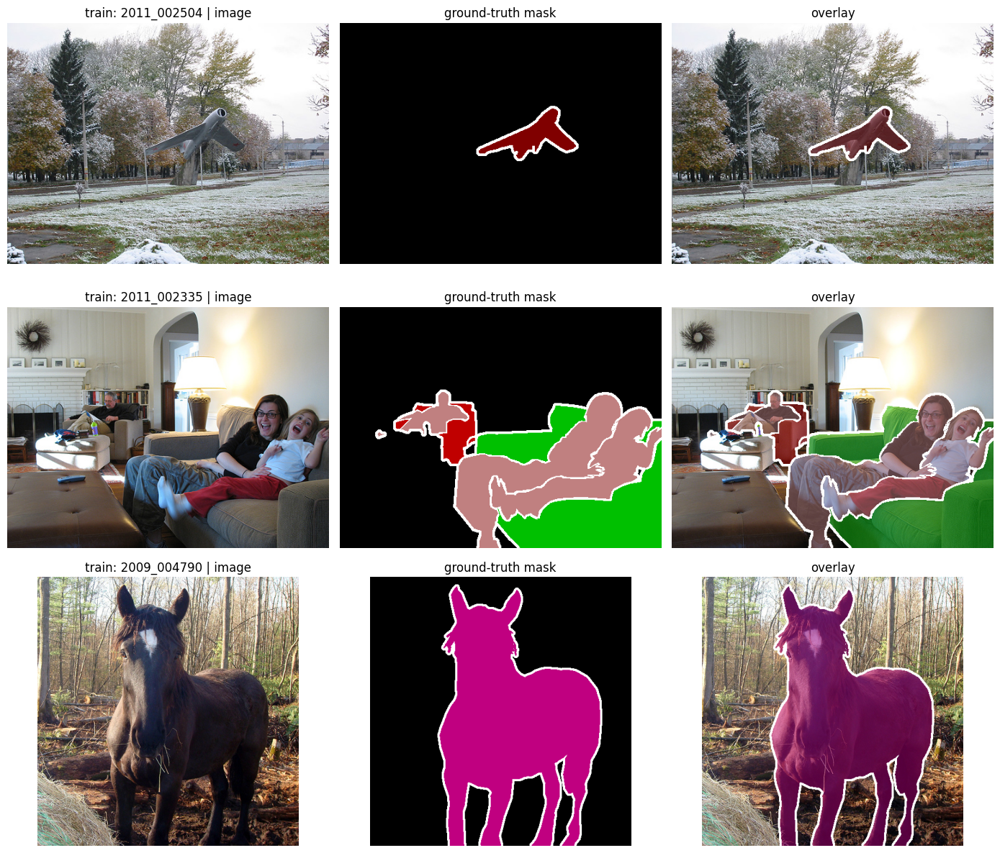

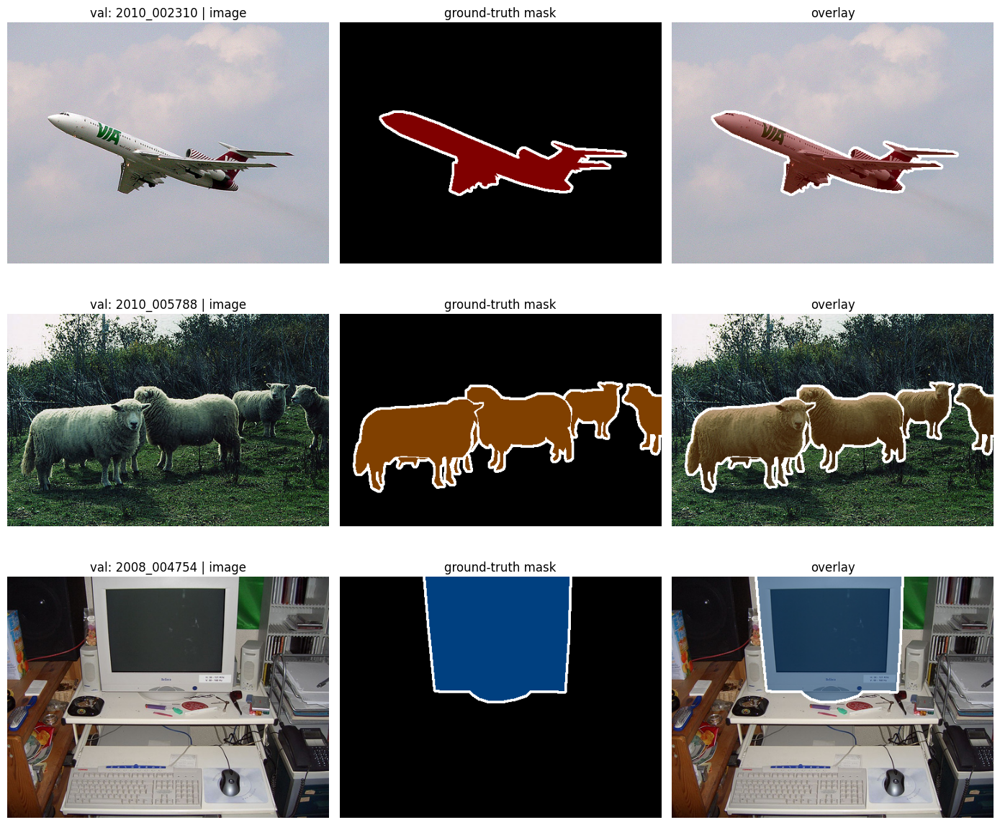

In [14]:
def show_random_samples(df: pd.DataFrame, subset: str, n_samples: int = 3) -> None:
    sampled_df = df[df["subset"] == subset].sample(min(n_samples, (df["subset"] == subset).sum()), random_state=SEED)
    fig, axes = plt.subplots(len(sampled_df), 3, figsize=(14, 4 * len(sampled_df)))
    if len(sampled_df) == 1:
        axes = np.expand_dims(axes, axis=0)

    for ax_row, (_, row) in zip(axes, sampled_df.iterrows()):
        image = np.array(Image.open(row["image_path"]).convert("RGB"))
        mask = np.array(Image.open(row["mask_path"]))
        overlay = overlay_mask(image, mask)

        ax_row[0].imshow(image)
        ax_row[0].set_title(f"{subset}: {row['image_id']} | image")
        ax_row[1].imshow(decode_target(mask))
        ax_row[1].set_title("ground-truth mask")
        ax_row[2].imshow(overlay)
        ax_row[2].set_title("overlay")

        for ax in ax_row:
            ax.axis("off")

    plt.tight_layout()
    plt.show()


show_random_samples(split_df, subset="train", n_samples=3)
show_random_samples(split_df, subset="val", n_samples=3)

##  SSL Model Setup (DINOv2 + FPN)

In [15]:
SSL_IMAGE_SIZE = 336 
NUM_CLASSES = 21
IGNORE_INDEX = 255
DINO_REPO_OR_DIR = "facebookresearch/dinov2"
DINO_BACKBONE_NAME = "dinov2_vits14"
DINO_PATCH_SIZE = 14
DINO_OUT_INDICES = (2, 5, 8, 11)
PYRAMID_CHANNELS = 192
SEGMENTATION_CHANNELS = 128
CHECKPOINT_DIR = Path("/kaggle/working")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

In [16]:
ssl_train_tfms = A.Compose([
    A.Resize(SSL_IMAGE_SIZE, SSL_IMAGE_SIZE),
    A.HorizontalFlip(p=0.5),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])
ssl_val_tfms = A.Compose([
    A.Resize(SSL_IMAGE_SIZE, SSL_IMAGE_SIZE),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

ssl_dm = LitVOCDataModule(
    split_df,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    train_tfms=ssl_train_tfms,
    val_tfms=ssl_val_tfms,
)
ssl_dm.setup()

In [17]:
class ConvBNReLU(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, kernel_size: int = 3):
        super().__init__()
        padding = kernel_size // 2
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=kernel_size, padding=padding, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.block(x)

In [18]:
class FPNDecoder(nn.Module):
    def __init__(self, encoder_channels: list[int], pyramid_channels: int = 256):
        super().__init__()
        self.lateral_convs = nn.ModuleList([
            nn.Conv2d(ch, pyramid_channels, kernel_size=1)
            for ch in encoder_channels
        ])
        self.output_convs = nn.ModuleList([
            nn.Conv2d(pyramid_channels, pyramid_channels, kernel_size=3, padding=1)
            for _ in encoder_channels
        ])

    def forward(self, features: list[torch.Tensor]) -> list[torch.Tensor]:
        laterals = [lat_conv(feature) for lat_conv, feature in zip(self.lateral_convs, features)]
        pyramid = [None] * len(laterals)
        pyramid[-1] = laterals[-1]

        for idx in range(len(laterals) - 2, -1, -1):
            upsampled = F.interpolate(
                pyramid[idx + 1],
                size=laterals[idx].shape[-2:],
                mode="nearest",
            )
            pyramid[idx] = laterals[idx] + upsampled

        return [conv(feature) for conv, feature in zip(self.output_convs, pyramid)]

In [19]:
class FPNSegmentationHead(nn.Module):
    def __init__(
        self,
        num_levels: int,
        pyramid_channels: int = 256,
        segmentation_channels: int = 128,
        num_classes: int = 21,
        dropout: float = 0.1,
    ):
        super().__init__()
        self.blocks = nn.ModuleList([
            ConvBNReLU(pyramid_channels, segmentation_channels, kernel_size=3)
            for _ in range(num_levels)
        ])
        self.fuse = nn.Sequential(
            ConvBNReLU(num_levels * segmentation_channels, segmentation_channels, kernel_size=3),
            nn.Dropout2d(dropout) if dropout > 0 else nn.Identity(),
            nn.Conv2d(segmentation_channels, num_classes, kernel_size=1),
        )

    def forward(self, pyramid_features: list[torch.Tensor]) -> torch.Tensor:
        target_size = pyramid_features[0].shape[-2:]
        fused_features = []

        for feature, block in zip(pyramid_features, self.blocks):
            x = block(feature)
            if x.shape[-2:] != target_size:
                x = F.interpolate(x, size=target_size, mode="bilinear", align_corners=False)
            fused_features.append(x)

        return self.fuse(torch.cat(fused_features, dim=1))


In [20]:
class DINOv2FpnSegmentationModel(nn.Module):
    def __init__(
        self,
        repo_or_dir: str,
        backbone_name: str,
        num_classes: int,
        patch_size: int = 14,
        out_indices: Sequence[int] = (2, 5, 8, 11),
        pyramid_channels: int = 192,
        segmentation_channels: int = 128,
        freeze_backbone: bool = True,
        trainable_blocks: int = 0,
    ):
        super().__init__()
        self.repo_or_dir = repo_or_dir
        self.backbone_name = backbone_name
        self.patch_size = patch_size
        self.out_indices = tuple(out_indices)
        self.backbone = torch.hub.load(repo_or_dir=self.repo_or_dir, model=self.backbone_name)
        self.embed_dim = self._infer_embed_dim()

        self.decoder = FPNDecoder(
            encoder_channels=[self.embed_dim] * len(self.out_indices),
            pyramid_channels=pyramid_channels,
        )
        self.segmentation_head = FPNSegmentationHead(
            num_levels=len(self.out_indices),
            pyramid_channels=pyramid_channels,
            segmentation_channels=segmentation_channels,
            num_classes=num_classes,
        )
        self.set_backbone_trainability(freeze_backbone=freeze_backbone, trainable_blocks=trainable_blocks)

    def _infer_embed_dim(self) -> int:
        for attr in ["embed_dim", "num_features"]:
            if hasattr(self.backbone, attr):
                return int(getattr(self.backbone, attr))
        if hasattr(self.backbone, "blocks") and len(self.backbone.blocks) > 0:
            normalized_shape = self.backbone.blocks[0].norm1.normalized_shape
            return int(normalized_shape[0] if isinstance(normalized_shape, (tuple, list)) else normalized_shape)
        raise RuntimeError("Could not infer DINOv2 embedding dimension.")

    def set_backbone_trainability(self, freeze_backbone: bool = True, trainable_blocks: int = 0) -> None:
        for param in self.backbone.parameters():
            param.requires_grad = not freeze_backbone

        if freeze_backbone:
            for param in self.backbone.parameters():
                param.requires_grad = False

        if trainable_blocks > 0 and hasattr(self.backbone, "blocks"):
            for block in self.backbone.blocks[-trainable_blocks:]:
                for param in block.parameters():
                    param.requires_grad = True
            if hasattr(self.backbone, "norm"):
                for param in self.backbone.norm.parameters():
                    param.requires_grad = True

    def _tokens_to_map(self, tokens: torch.Tensor, input_size: tuple[int, int]) -> torch.Tensor:
        input_h, input_w = input_size
        grid_h = input_h // self.patch_size
        grid_w = input_w // self.patch_size
        batch_size, num_tokens, channels = tokens.shape
        expected_tokens = grid_h * grid_w
        if num_tokens != expected_tokens:
            raise RuntimeError(
                f"Token count mismatch: got {num_tokens}, expected {expected_tokens} for input {input_size}."
            )
        return tokens.transpose(1, 2).reshape(batch_size, channels, grid_h, grid_w)

    def _extract_token_features(self, x: torch.Tensor) -> list[torch.Tensor]:
        features = self.backbone.get_intermediate_layers(
            x,
            n=self.out_indices,
            reshape=False,
            return_class_token=False,
        )
        if isinstance(features, torch.Tensor):
            features = [features]
        token_features = []
        for feature in features:
            if isinstance(feature, (tuple, list)):
                feature = feature[0]
            token_features.append(feature)
        return token_features

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        input_size = x.shape[-2:]
        if input_size[0] % self.patch_size != 0 or input_size[1] % self.patch_size != 0:
            raise ValueError(f"Input size must be divisible by patch_size={self.patch_size}, got {input_size}.")

        if any(param.requires_grad for param in self.backbone.parameters()):
            token_features = self._extract_token_features(x)
        else:
            with torch.no_grad():
                token_features = self._extract_token_features(x)

        feature_maps = [self._tokens_to_map(tokens, input_size) for tokens in token_features]
        pyramid = self.decoder(feature_maps)
        logits = self.segmentation_head(pyramid)
        logits = F.interpolate(logits, size=input_size, mode="bilinear", align_corners=False)
        return logits


In [21]:
def count_trainable_params(model: nn.Module) -> dict[str, int]:
    total = sum(param.numel() for param in model.parameters())
    trainable = sum(param.numel() for param in model.parameters() if param.requires_grad)
    backbone = sum(param.numel() for param in model.backbone.parameters())
    trainable_backbone = sum(param.numel() for param in model.backbone.parameters() if param.requires_grad)
    head_trainable = trainable - trainable_backbone
    return {
        "total": total,
        "trainable": trainable,
        "backbone": backbone,
        "trainable_backbone": trainable_backbone,
        "trainable_head": head_trainable,
    }

In [22]:
frozen_ssl_model = DINOv2FpnSegmentationModel(
    repo_or_dir=DINO_REPO_OR_DIR,
    backbone_name=DINO_BACKBONE_NAME,
    num_classes=NUM_CLASSES,
    patch_size=DINO_PATCH_SIZE,
    out_indices=DINO_OUT_INDICES,
    pyramid_channels=PYRAMID_CHANNELS,
    segmentation_channels=SEGMENTATION_CHANNELS,
    freeze_backbone=True,
    trainable_blocks=0,
).to(DEVICE)

param_stats = count_trainable_params(frozen_ssl_model)
pd.Series(param_stats, name="frozen_ssl_model")

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 254MB/s]


total                 25158677
trainable              3102101
backbone              22056576
trainable_backbone           0
trainable_head         3102101
Name: frozen_ssl_model, dtype: int64

## Training Loop (Frozen Backbone)

In [23]:
def compute_confusion_matrix(
    predictions: torch.Tensor,
    targets: torch.Tensor,
    num_classes: int,
    ignore_index: int = 255,
) -> torch.Tensor:
    valid_mask = targets != ignore_index
    predictions = predictions[valid_mask]
    targets = targets[valid_mask]

    if targets.numel() == 0:
        return torch.zeros((num_classes, num_classes), dtype=torch.float64)

    indices = targets * num_classes + predictions
    confusion = torch.bincount(indices, minlength=num_classes ** 2)
    return confusion.reshape(num_classes, num_classes).to(torch.float64)


def metrics_from_confusion(confusion: torch.Tensor) -> dict[str, object]:
    true_positive = torch.diag(confusion)
    false_positive = confusion.sum(dim=0) - true_positive
    false_negative = confusion.sum(dim=1) - true_positive

    union = true_positive + false_positive + false_negative
    denom_dice = 2 * true_positive + false_positive + false_negative

    iou_per_class = torch.where(union > 0, true_positive / union, torch.nan)
    dice_per_class = torch.where(denom_dice > 0, 2 * true_positive / denom_dice, torch.nan)

    return {
        "mIoU": float(torch.nanmean(iou_per_class).item()),
        "Dice": float(torch.nanmean(dice_per_class).item()),
        "iou_per_class": {
            VOC_CLASSES[class_idx]: float(iou_per_class[class_idx].item())
            for class_idx in range(NUM_CLASSES)
            if not torch.isnan(iou_per_class[class_idx])
        },
        "dice_per_class": {
            VOC_CLASSES[class_idx]: float(dice_per_class[class_idx].item())
            for class_idx in range(NUM_CLASSES)
            if not torch.isnan(dice_per_class[class_idx])
        },
    }

In [24]:
@torch.no_grad()
def evaluate_segmentation_model(
    model: nn.Module,
    dataloader: torch.utils.data.DataLoader,
    criterion: nn.Module,
    device: str,
    num_classes: int = NUM_CLASSES,
    ignore_index: int = IGNORE_INDEX,
) -> dict[str, object]:
    model.eval()
    confusion = torch.zeros((num_classes, num_classes), dtype=torch.float64)
    total_loss = 0.0
    total_batches = 0

    for images, masks, _ in tqdm(dataloader, desc="val", leave=False):
        images = images.to(device)
        masks = masks.to(device)
        logits = model(images)
        loss = criterion(logits, masks)
        predictions = logits.argmax(dim=1)

        confusion += compute_confusion_matrix(predictions.cpu(), masks.cpu(), num_classes, ignore_index)
        total_loss += float(loss.item())
        total_batches += 1

    metrics = metrics_from_confusion(confusion)
    metrics["loss"] = total_loss / max(total_batches, 1)
    return metrics

In [25]:
def build_optimizer(
    model: DINOv2FpnSegmentationModel,
    backbone_lr: float,
    head_lr: float,
    weight_decay: float,
) -> torch.optim.Optimizer:
    head_params = list(model.decoder.parameters()) + list(model.segmentation_head.parameters())
    backbone_params = [param for param in model.backbone.parameters() if param.requires_grad]
    param_groups = [{"params": head_params, "lr": head_lr, "weight_decay": weight_decay}]
    if backbone_params:
        param_groups.append({"params": backbone_params, "lr": backbone_lr, "weight_decay": weight_decay})
    return torch.optim.AdamW(param_groups)

In [26]:
def train_ssl_segmentation(
    model: DINOv2FpnSegmentationModel,
    datamodule: LitVOCDataModule,
    config: dict,
) -> tuple[pd.DataFrame, Path]:
    train_loader = datamodule.train_dataloader()
    val_loader = datamodule.val_dataloader()
    criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
    optimizer = build_optimizer(
        model,
        backbone_lr=config["backbone_lr"],
        head_lr=config["head_lr"],
        weight_decay=config["weight_decay"],
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=config["epochs"])
    best_val_miou = -float("inf")
    best_model_path = CHECKPOINT_DIR / config["checkpoint_name"]
    history = []

    for epoch in range(1, config["epochs"] + 1):
        model.train()
        train_loss = 0.0
        train_batches = 0

        for images, masks, _ in tqdm(train_loader, desc=f"train epoch {epoch}", leave=False):
            images = images.to(DEVICE)
            masks = masks.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, masks)
            loss.backward()
            optimizer.step()
            train_loss += float(loss.item())
            train_batches += 1

        scheduler.step()
        train_loss /= max(train_batches, 1)
        val_metrics = evaluate_segmentation_model(model, val_loader, criterion, DEVICE)

        row = {
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_metrics["loss"],
            "val_mIoU": val_metrics["mIoU"],
            "val_Dice": val_metrics["Dice"],
            "head_lr": optimizer.param_groups[0]["lr"],
            "backbone_lr": optimizer.param_groups[1]["lr"] if len(optimizer.param_groups) > 1 else 0.0,
        }
        history.append(row)
        print(row)

        if val_metrics["mIoU"] > best_val_miou:
            best_val_miou = val_metrics["mIoU"]
            checkpoint_payload = {
                "epoch": epoch,
                "model_state_dict": deepcopy(model.state_dict()),
                "config": config,
                "val_metrics": val_metrics,
            }
            torch.save(checkpoint_payload, best_model_path)

    history_df = pd.DataFrame(history)

    return history_df, best_model_path

In [27]:
frozen_train_config = {
    "epochs": 15,
    "head_lr": 1e-3,
    "backbone_lr": 0.0,
    "weight_decay": 1e-4,
    "checkpoint_name": "best_dinov2_fpn_frozen.pth",
}

In [28]:
frozen_history_df, frozen_best_model_path = train_ssl_segmentation(
    frozen_ssl_model,
    ssl_dm,
    frozen_train_config,
)

train epoch 1:   0%|          | 0/183 [00:00<?, ?it/s]

val:   0%|          | 0/182 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 0.7431092473978553, 'val_loss': 0.26294681270207676, 'val_mIoU': 0.6156349002581174, 'val_Dice': 0.7170026310934217, 'head_lr': 0.0009890738003669028, 'backbone_lr': 0.0}


train epoch 2:   0%|          | 0/183 [00:00<?, ?it/s]

val:   0%|          | 0/182 [00:00<?, ?it/s]

...

val:   0%|          | 0/182 [00:00<?, ?it/s]

{'epoch': 14, 'train_loss': 0.06751304584977731, 'val_loss': 0.10989353230611963, 'val_mIoU': 0.8335591469140983, 'val_Dice': 0.9039366260477993, 'head_lr': 1.0926199633097156e-05, 'backbone_lr': 0.0}


train epoch 15:   0%|          | 0/183 [00:00<?, ?it/s]

val:   0%|          | 0/182 [00:00<?, ?it/s]

{'epoch': 15, 'train_loss': 0.06622021063103702, 'val_loss': 0.10983061562241106, 'val_mIoU': 0.8333444838467176, 'val_Dice': 0.9037671830198035, 'head_lr': 0.0, 'backbone_lr': 0.0}


In [29]:
best_checkpoint = torch.load(frozen_best_model_path, map_location=DEVICE)
frozen_ssl_model.load_state_dict(best_checkpoint["model_state_dict"])
criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
frozen_val_metrics = evaluate_segmentation_model(
    frozen_ssl_model,
    ssl_dm.val_dataloader(),
    criterion,
    DEVICE,
)

val:   0%|          | 0/182 [00:00<?, ?it/s]

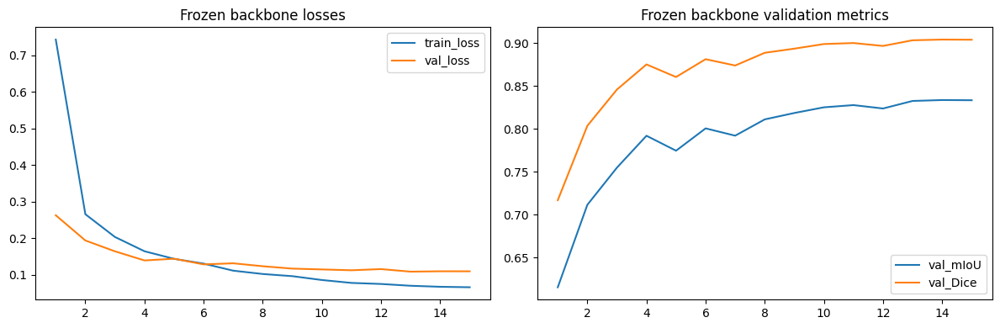

best_checkpoint    /kaggle/working/best_dinov2_fpn_frozen.pth
val_mIoU                                             0.833559
val_Dice                                             0.903937
val_loss                                             0.109894
dtype: object

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(frozen_history_df["epoch"], frozen_history_df["train_loss"], label="train_loss")
axes[0].plot(frozen_history_df["epoch"], frozen_history_df["val_loss"], label="val_loss")
axes[0].set_title("Frozen backbone losses")
axes[0].legend()
axes[1].plot(frozen_history_df["epoch"], frozen_history_df["val_mIoU"], label="val_mIoU")
axes[1].plot(frozen_history_df["epoch"], frozen_history_df["val_Dice"], label="val_Dice")
axes[1].set_title("Frozen backbone validation metrics")
axes[1].legend()
plt.tight_layout()
plt.show()

frozen_summary = {
    "best_checkpoint": str(frozen_best_model_path),
    "val_mIoU": frozen_val_metrics["mIoU"],
    "val_Dice": frozen_val_metrics["Dice"],
    "val_loss": frozen_val_metrics["loss"],
}

pd.Series(frozen_summary)

In [31]:
def predict_mask_for_row(
    model: nn.Module,
    row: pd.Series,
    transform,
    device: str,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    image = np.array(Image.open(row["image_path"]).convert("RGB"))
    mask = np.array(Image.open(row["mask_path"]))
    transformed = transform(image=image, mask=mask)
    image_tensor = transformed["image"].unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        logits = model(image_tensor)
        prediction = logits.argmax(dim=1, keepdim=True).float()
        prediction = F.interpolate(
            prediction,
            size=mask.shape,
            mode="nearest",
        ).squeeze().cpu().numpy().astype(np.uint8)

    return image, mask, prediction


def compute_sample_iou(prediction: np.ndarray, target: np.ndarray, num_classes: int = NUM_CLASSES, ignore_index: int = IGNORE_INDEX) -> float:
    valid_mask = target != ignore_index
    prediction = prediction[valid_mask]
    target = target[valid_mask]
    if target.size == 0:
        return float("nan")

    ious = []
    for class_idx in range(num_classes):
        pred_mask = prediction == class_idx
        tgt_mask = target == class_idx
        union = np.logical_or(pred_mask, tgt_mask).sum()
        if union == 0:
            continue
        intersection = np.logical_and(pred_mask, tgt_mask).sum()
        ious.append(intersection / union)

    return float(np.mean(ious)) if ious else float("nan")


def collect_hard_samples(
    model: nn.Module,
    df: pd.DataFrame,
    transform,
    device: str,
    subset: str = "val",
    top_k: int = 5,
) -> tuple[pd.DataFrame, list[dict[str, np.ndarray]]]:
    rows = []
    visual_payload = []
    subset_df = df[df["subset"] == subset].reset_index(drop=True)

    for _, row in tqdm(subset_df.iterrows(), total=len(subset_df), desc="hard-sample scan", leave=False):
        image, mask, prediction = predict_mask_for_row(model, row, transform, device)
        sample_iou = compute_sample_iou(prediction, mask)
        rows.append({"image_id": row["image_id"], "subset": subset, "sample_iou": sample_iou})
        visual_payload.append({
            "image_id": row["image_id"],
            "image": image,
            "mask": mask,
            "prediction": prediction,
            "sample_iou": sample_iou,
        })

    hard_df = pd.DataFrame(rows).sort_values("sample_iou", ascending=True).reset_index(drop=True)
    top_ids = set(hard_df.head(top_k)["image_id"])
    top_payload = [item for item in visual_payload if item["image_id"] in top_ids]
    top_payload = sorted(top_payload, key=lambda item: item["sample_iou"])
    return hard_df, top_payload


def show_prediction_gallery(payload: list[dict[str, np.ndarray]], title_prefix: str = "prediction") -> None:
    if not payload:
        print("No samples to display.")
        return

    fig, axes = plt.subplots(len(payload), 3, figsize=(14, 4 * len(payload)))
    if len(payload) == 1:
        axes = np.expand_dims(axes, axis=0)

    for ax_row, item in zip(axes, payload):
        ax_row[0].imshow(item["image"])
        ax_row[0].set_title(f"{item['image_id']} | image")
        ax_row[1].imshow(decode_target(item["mask"]))
        ax_row[1].set_title("ground-truth mask")
        ax_row[2].imshow(decode_target(item["prediction"]))
        ax_row[2].set_title(f"{title_prefix} | IoU={item['sample_iou']:.4f}")
        for ax in ax_row:
            ax.axis("off")

    plt.tight_layout()
    plt.show()

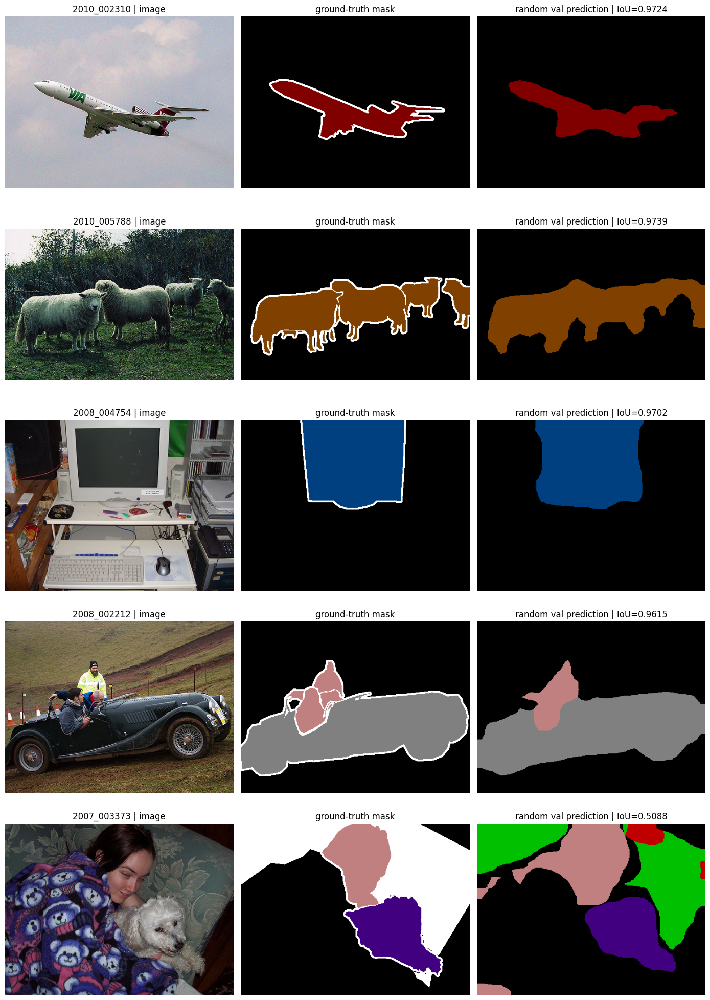

In [32]:
random_val_rows = split_df[split_df["subset"] == "val"].sample(5, random_state=SEED)
qualitative_payload = []
for _, row in random_val_rows.iterrows():
    image, mask, prediction = predict_mask_for_row(frozen_ssl_model, row, ssl_val_tfms, DEVICE)
    qualitative_payload.append({
        "image_id": row["image_id"],
        "image": image,
        "mask": mask,
        "prediction": prediction,
        "sample_iou": compute_sample_iou(prediction, mask),
    })

show_prediction_gallery(qualitative_payload, title_prefix="random val prediction")

hard-sample scan:   0%|          | 0/1449 [00:00<?, ?it/s]

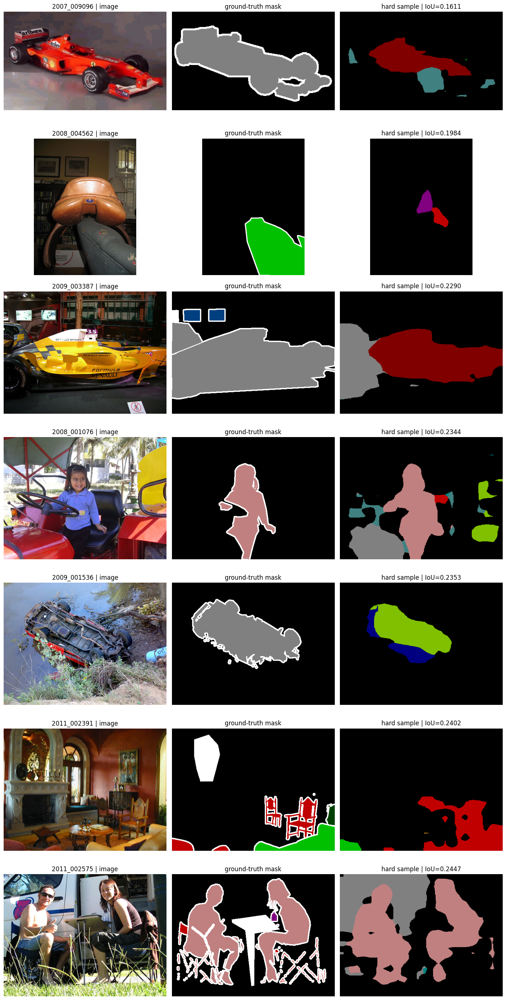

In [33]:
hard_samples_df, hard_sample_payload = collect_hard_samples(
    frozen_ssl_model,
    split_df,
    ssl_val_tfms,
    DEVICE,
    subset="val",
    top_k=7,
)

show_prediction_gallery(hard_sample_payload, title_prefix="hard sample")

# Partial Finetune Run

In [34]:
def build_ssl_model_from_config(config: dict) -> DINOv2FpnSegmentationModel:
    return DINOv2FpnSegmentationModel(
        repo_or_dir=DINO_REPO_OR_DIR,
        backbone_name=DINO_BACKBONE_NAME,
        num_classes=NUM_CLASSES,
        patch_size=DINO_PATCH_SIZE,
        out_indices=DINO_OUT_INDICES,
        pyramid_channels=PYRAMID_CHANNELS,
        segmentation_channels=SEGMENTATION_CHANNELS,
        freeze_backbone=config["freeze_backbone"],
        trainable_blocks=config["trainable_blocks"],
    ).to(DEVICE)

In [35]:
partial_finetune_config = {
    "freeze_backbone": False,
    "trainable_blocks": 2,
    "epochs": 15,
    "head_lr": 3e-4,
    "backbone_lr": 1e-5,
    "weight_decay": 1e-4,
    "checkpoint_name": "best_dinov2_fpn_partial_ft.pth",
}

In [36]:
partial_ssl_model = build_ssl_model_from_config(partial_finetune_config)
partial_param_stats = pd.Series(count_trainable_params(partial_ssl_model), name="partial_ssl_model")
partial_param_stats

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


total                 25158677
trainable             25158677
backbone              22056576
trainable_backbone    22056576
trainable_head         3102101
Name: partial_ssl_model, dtype: int64

In [37]:
partial_history_df, partial_best_model_path = train_ssl_segmentation(
    partial_ssl_model,
    ssl_dm,
    partial_finetune_config,
)

train epoch 1:   0%|          | 0/183 [00:00<?, ?it/s]

val:   0%|          | 0/182 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 1.0378285265359721, 'val_loss': 0.38082800060510635, 'val_mIoU': 0.6141839209258394, 'val_Dice': 0.7177795245559276, 'head_lr': 0.0002967221401100708, 'backbone_lr': 9.890738003669029e-06}


train epoch 2:   0%|          | 0/183 [00:00<?, ?it/s]

val:   0%|          | 0/182 [00:00<?, ?it/s]

...

val:   0%|          | 0/182 [00:00<?, ?it/s]

{'epoch': 14, 'train_loss': 0.04236588798096923, 'val_loss': 0.1271653354096298, 'val_mIoU': 0.8326876453142054, 'val_Dice': 0.9040809149723172, 'head_lr': 3.2778598899291478e-06, 'backbone_lr': 1.092619963309716e-07}


train epoch 15:   0%|          | 0/183 [00:00<?, ?it/s]

val:   0%|          | 0/182 [00:00<?, ?it/s]

{'epoch': 15, 'train_loss': 0.041070312292116586, 'val_loss': 0.12564752574825844, 'val_mIoU': 0.8326273474640645, 'val_Dice': 0.9038138638417872, 'head_lr': 0.0, 'backbone_lr': 0.0}


In [38]:
partial_best_checkpoint = torch.load(partial_best_model_path, map_location=DEVICE)
partial_ssl_model.load_state_dict(partial_best_checkpoint["model_state_dict"])
criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
partial_val_metrics = evaluate_segmentation_model(
    partial_ssl_model,
    ssl_dm.val_dataloader(),
    criterion,
    DEVICE,
)

val:   0%|          | 0/182 [00:00<?, ?it/s]

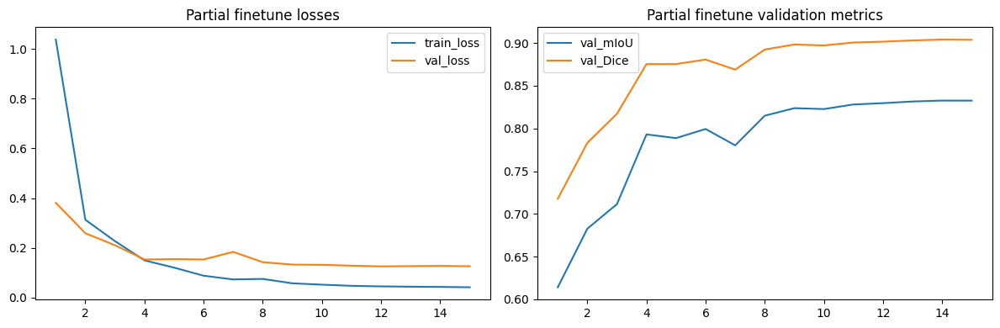

best_checkpoint    /kaggle/working/best_dinov2_fpn_partial_ft.pth
val_mIoU                                                 0.832688
val_Dice                                                 0.904081
val_loss                                                 0.127165
epochs                                                         15
dtype: object

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(partial_history_df["epoch"], partial_history_df["train_loss"], label="train_loss")
axes[0].plot(partial_history_df["epoch"], partial_history_df["val_loss"], label="val_loss")
axes[0].set_title("Partial finetune losses")
axes[0].legend()
axes[1].plot(partial_history_df["epoch"], partial_history_df["val_mIoU"], label="val_mIoU")
axes[1].plot(partial_history_df["epoch"], partial_history_df["val_Dice"], label="val_Dice")
axes[1].set_title("Partial finetune validation metrics")
axes[1].legend()
plt.tight_layout()
plt.show()

partial_summary = {
    "best_checkpoint": str(partial_best_model_path),
    "val_mIoU": partial_val_metrics["mIoU"],
    "val_Dice": partial_val_metrics["Dice"],
    "val_loss": partial_val_metrics["loss"],
    "epochs": partial_finetune_config["epochs"],
}

pd.Series(partial_summary)

In [40]:
frozen_summary_with_meta = {
    **frozen_summary,
    "epochs": frozen_train_config["epochs"],
    "mode": "frozen",
}
partial_summary_with_meta = {
    **partial_summary,
    "mode": "partial_finetune",
}

comparison_df = pd.DataFrame([
    frozen_summary_with_meta,
    partial_summary_with_meta,
]).set_index("mode")

metric_delta_df = pd.DataFrame({
    "metric": ["val_mIoU", "val_Dice", "val_loss"],
    "frozen": [comparison_df.loc["frozen", "val_mIoU"], comparison_df.loc["frozen", "val_Dice"], comparison_df.loc["frozen", "val_loss"]],
    "partial_finetune": [comparison_df.loc["partial_finetune", "val_mIoU"], comparison_df.loc["partial_finetune", "val_Dice"], comparison_df.loc["partial_finetune", "val_loss"]],
})
metric_delta_df["delta_partial_minus_frozen"] = metric_delta_df["partial_finetune"] - metric_delta_df["frozen"]
metric_delta_df

,metric,frozen,partial_finetune,delta_partial_minus_frozen
0,val_mIoU,0.833559,0.832688,-0.000872
1,val_Dice,0.903937,0.904081,0.000144
2,val_loss,0.109894,0.127165,0.017272


In [41]:
def show_model_comparison_gallery(
    frozen_model: nn.Module,
    partial_model: nn.Module,
    df: pd.DataFrame,
    image_ids: list[str],
    transform,
    device: str,
) -> None:
    rows = df[df["image_id"].isin(image_ids)].drop_duplicates("image_id").set_index("image_id").loc[image_ids].reset_index()
    fig, axes = plt.subplots(len(rows), 4, figsize=(18, 4 * len(rows)))
    if len(rows) == 1:
        axes = np.expand_dims(axes, axis=0)

    for ax_row, (_, row) in zip(axes, rows.iterrows()):
        image, mask, frozen_prediction = predict_mask_for_row(frozen_model, row, transform, device)
        _, _, partial_prediction = predict_mask_for_row(partial_model, row, transform, device)
        frozen_iou = compute_sample_iou(frozen_prediction, mask)
        partial_iou = compute_sample_iou(partial_prediction, mask)

        ax_row[0].imshow(image)
        ax_row[0].set_title(f"{row['image_id']} | image")
        ax_row[1].imshow(decode_target(mask))
        ax_row[1].set_title("ground-truth mask")
        ax_row[2].imshow(decode_target(frozen_prediction))
        ax_row[2].set_title(f"frozen | IoU={frozen_iou:.4f}")
        ax_row[3].imshow(decode_target(partial_prediction))
        ax_row[3].set_title(f"partial | IoU={partial_iou:.4f}")

        for ax in ax_row:
            ax.axis("off")

    plt.tight_layout()
    plt.show()

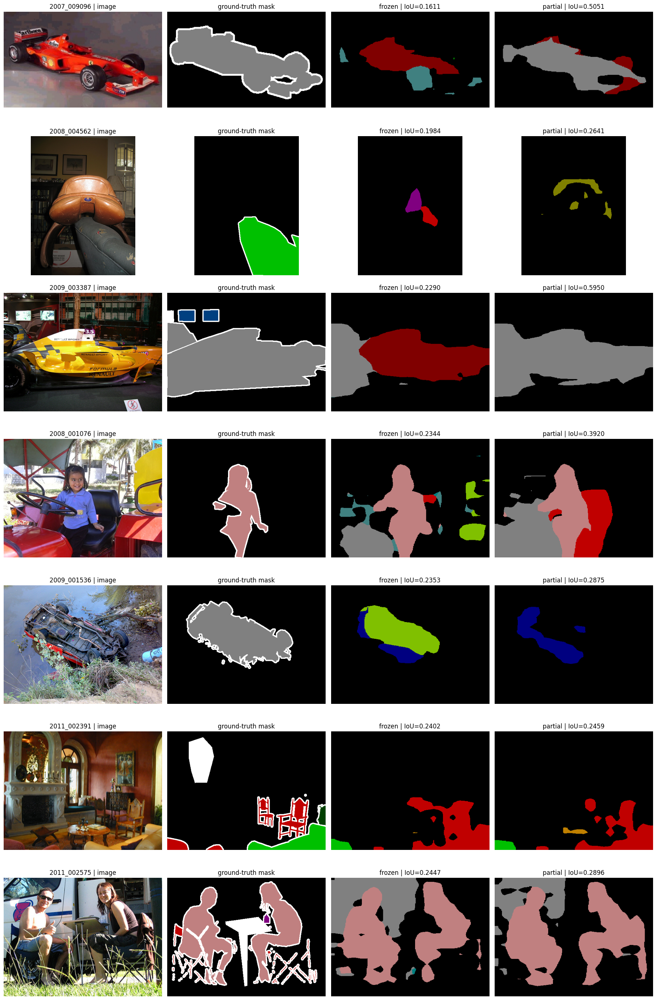

In [42]:
compare_image_ids = hard_samples_df.head(7)["image_id"].tolist()

show_model_comparison_gallery(
    frozen_ssl_model,
    partial_ssl_model,
    split_df,
    compare_image_ids,
    ssl_val_tfms,
    DEVICE,
)

In [43]:
report_table_df = comparison_df.reset_index()[[
    "mode",
    "epochs",
    "val_mIoU",
    "val_Dice",
    "val_loss",
    "best_checkpoint",
]].copy()
report_table_df["val_mIoU"] = report_table_df["val_mIoU"].map(lambda x: round(float(x), 6))
report_table_df["val_Dice"] = report_table_df["val_Dice"].map(lambda x: round(float(x), 6))
report_table_df["val_loss"] = report_table_df["val_loss"].map(lambda x: round(float(x), 6))

report_delta_df = metric_delta_df.copy()
report_delta_df["frozen"] = report_delta_df["frozen"].map(lambda x: round(float(x), 6))
report_delta_df["partial_finetune"] = report_delta_df["partial_finetune"].map(lambda x: round(float(x), 6))
report_delta_df["delta_partial_minus_frozen"] = report_delta_df["delta_partial_minus_frozen"].map(lambda x: round(float(x), 6))
report_delta_df

,metric,frozen,partial_finetune,delta_partial_minus_frozen
0,val_mIoU,0.833559,0.832688,-0.000872
1,val_Dice,0.903937,0.904081,0.000144
2,val_loss,0.109894,0.127165,0.017272


In [44]:
frozen_iou_series = pd.Series(frozen_val_metrics["iou_per_class"], name="frozen")
partial_iou_series = pd.Series(partial_val_metrics["iou_per_class"], name="partial_finetune")

report_per_class_iou_df = pd.concat([frozen_iou_series, partial_iou_series], axis=1)
report_per_class_iou_df = report_per_class_iou_df.sort_index()
report_per_class_iou_df["delta_partial_minus_frozen"] = (
    report_per_class_iou_df["partial_finetune"] - report_per_class_iou_df["frozen"]
)

report_per_class_iou_df = report_per_class_iou_df.reset_index().rename(columns={"index": "class_name"})
for col in ["frozen", "partial_finetune", "delta_partial_minus_frozen"]:
    report_per_class_iou_df[col] = report_per_class_iou_df[col].map(lambda x: round(float(x), 6))

report_per_class_iou_df

,class_name,frozen,partial_finetune,delta_partial_minus_frozen
0,aeroplane,0.895980,0.923889,0.027909
1,background,0.960382,0.962435,0.002053
2,bicycle,0.603264,0.639372,0.036108
3,bird,0.932898,0.920460,-0.012438
4,boat,0.813180,0.811857,-0.001323
5,bottle,0.834709,0.885202,0.050493
6,bus,0.936138,0.906987,-0.029151
7,car,0.877879,0.899480,0.021600
8,cat,0.946937,0.893943,-0.052994
9,chair,0.522109,0.535830,0.013721


In [45]:
frozen_dice_series = pd.Series(frozen_val_metrics["dice_per_class"], name="frozen")
partial_dice_series = pd.Series(partial_val_metrics["dice_per_class"], name="partial_finetune")

report_per_class_dice_df = pd.concat([frozen_dice_series, partial_dice_series], axis=1)
report_per_class_dice_df = report_per_class_dice_df.sort_index()
report_per_class_dice_df["delta_partial_minus_frozen"] = (
    report_per_class_dice_df["partial_finetune"] - report_per_class_dice_df["frozen"]
)

report_per_class_dice_df = report_per_class_dice_df.reset_index().rename(columns={"index": "class_name"})
for col in ["frozen", "partial_finetune", "delta_partial_minus_frozen"]:
    report_per_class_dice_df[col] = report_per_class_dice_df[col].map(lambda x: round(float(x), 6))

report_per_class_dice_df

,class_name,frozen,partial_finetune,delta_partial_minus_frozen
0,aeroplane,0.945137,0.960439,0.015302
1,background,0.979791,0.980858,0.001068
2,bicycle,0.752545,0.780021,0.027476
3,bird,0.965284,0.958583,-0.006702
4,boat,0.896966,0.896160,-0.000806
5,bottle,0.909909,0.939106,0.029197
6,bus,0.967016,0.951225,-0.015791
7,car,0.934969,0.947080,0.012111
8,cat,0.972745,0.944002,-0.028743
9,chair,0.686034,0.697773,0.011739
